# Домашняя работа 1 — EDA датасета SMS Spam Collection
**Студент:** Паначева Татьяна Юрьевна

**Группа:** РИ-431001

## 1. Постановка задачи

### Бизнес-постановка
Мобильный оператор хочет автоматически фильтровать входящие SMS-сообщения
пользователей, помечая нежелательные (спам) сообщения. Это повысит
удовлетворённость клиентов и снизит количество жалоб.

### ML-постановка
Задача **бинарной классификации**: каждому SMS-сообщению нужно присвоить
один из двух классов — `spam` (спам) или `ham` (не спам).

### Набор данных
Используется датасет **SMS Spam Collection** (UCI Machine Learning Repository):
- 5572 SMS-сообщения
- 2 колонки: `label` (spam/ham) и `text` (текст сообщения)
- Ссылка: https://archive.ics.uci.edu/ml/datasets/sms+spam+collection

In [2]:
# Импорт библиотек

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стиля графиков
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Библиотеки импортированы")

✅ Библиотеки импортированы


###Источник данных и метод загрузки

Для решения задачи используется классический открытый датасет **SMS Spam Collection** из авторитетного архива **UCI Machine Learning Repository**.

🔗 **Официальная ссылка на датасет:**  
[https://archive.ics.uci.edu/ml/datasets/sms+spam+collection](https://archive.ics.uci.edu/ml/datasets/sms+spam+collection)

**Почему используется загрузка через `.zip` архив в коде:**  
Официальный репозиторий UCI предоставляет этот датасет исключительно в виде сжатого `.zip` архива. Вместо использования сторонних зеркал (например, копий на GitHub), в данном ноутбуке реализована прямая загрузка архива в оперативную память Google Colab с последующим чтением файла `SMSSpamCollection`.

Это гарантирует:
1. Работу с **оригинальными, неизмененными данными** из первоисточника.
2. **Полную воспроизводимость** кода в облачной среде без необходимости ручного скачивания и распаковки файлов на локальный диск.

In [6]:
import pandas as pd
import urllib.request
import zipfile
import io

# Официальная ссылка на архив UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

print("⏳ Скачиваем датасет с официального сайта UCI...")

# Скачиваем архив прямо в оперативную память (без сохранения на диск)
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    zip_data = response.read()

print("📦 Распаковываем и читаем данные...")

# Читаем файл 'SMSSpamCollection' из архива напрямую в pandas
with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    with z.open('SMSSpamCollection') as f:
        df = pd.read_csv(f, sep='\t', header=None, names=['label', 'text'], encoding='utf-8')

print(f"✅ Успешно загружено! Размер датасета: {df.shape[0]} строк, {df.shape[1]} колонок")
print("\nПервые 10 строк:")
df.head(10)

⏳ Скачиваем датасет с официального сайта UCI...
📦 Распаковываем и читаем данные...
✅ Успешно загружено! Размер датасета: 5572 строк, 2 колонок

Первые 10 строк:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [16]:
# Смотрим общую информацию о датасете
print("=" * 40)
print("БАЗОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ")
print("=" * 40)

print(f"\nТипы данных в колонках:")
print(df.dtypes)

print(f"\nПроверка на пропущенные значения (должно быть 0):")
print(df.isnull().sum())

print(f"\nРаспределение классов (абсолютные числа):")
print(df['label'].value_counts())

print(f"\nДоля каждого класса (%):")
print((df['label'].value_counts(normalize=True) * 100).round(1))

БАЗОВАЯ ИНФОРМАЦИЯ О ДАТАСЕТЕ

Типы данных в колонках:
label                object
text                 object
length                int64
word_count            int64
punctuation_count     int64
dtype: object

Проверка на пропущенные значения (должно быть 0):
label                0
text                 0
length               0
word_count           0
punctuation_count    0
dtype: int64

Распределение классов (абсолютные числа):
label
ham     4825
spam     747
Name: count, dtype: int64

Доля каждого класса (%):
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


/tmp/ipykernel_2189/2478720139.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, ax=axes[1], palette=['lightgreen', 'lightcoral'])


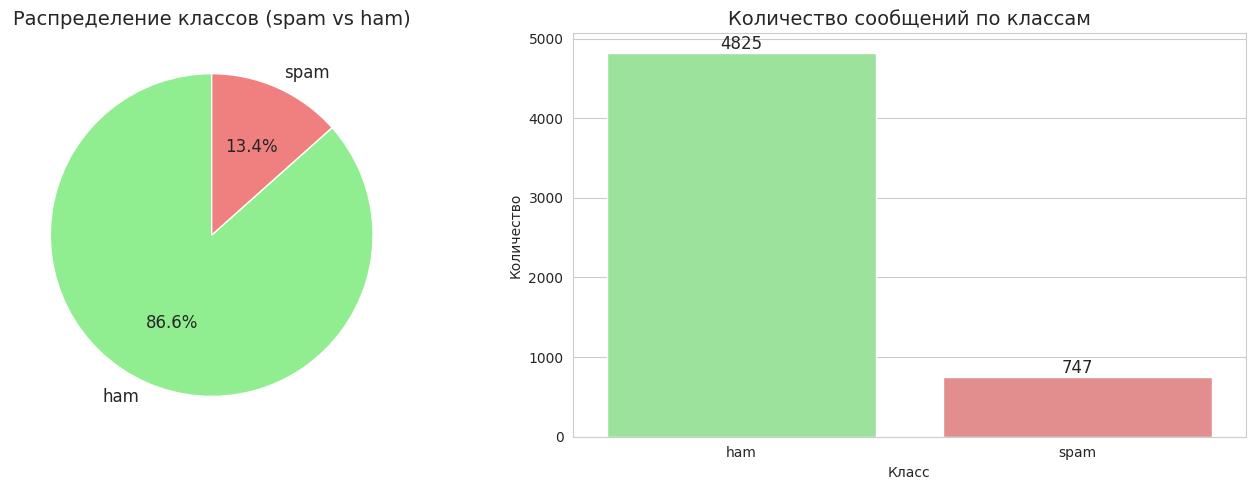


📊 ВЫВОД: Датасет несбалансирован — обычных сообщений (ham) значительно больше, чем спама.
   Это важно учесть при выборе метрики качества модели.


In [17]:
# Визуализация распределения классов (spam vs ham)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Круговая диаграмма
df['label'].value_counts().plot.pie(
    ax=axes[0],
    autopct='%1.1f%%',
    colors=['lightgreen', 'lightcoral'],
    startangle=90,
    fontsize=12
)
axes[0].set_title('Распределение классов (spam vs ham)', fontsize=14)
axes[0].set_ylabel('')

# Столбчатая диаграмма
sns.countplot(x='label', data=df, ax=axes[1], palette=['lightgreen', 'lightcoral'])
axes[1].set_title('Количество сообщений по классам', fontsize=14)
axes[1].set_xlabel('Класс')
axes[1].set_ylabel('Количество')

# Добавляем значения на столбцы
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

print("\n📊 ВЫВОД: Датасет несбалансирован — обычных сообщений (ham) значительно больше, чем спама.")
print("   Это важно учесть при выборе метрики качества модели.")

In [18]:
# Создаем новые числовые признаки на основе текста
df['length'] = df['text'].apply(len)  # Длина сообщения в символах
df['word_count'] = df['text'].apply(lambda x: len(x.split()))  # Количество слов
df['punctuation_count'] = df['text'].apply(
    lambda x: sum(1 for c in x if c in '!?.,;:')  # Количество знаков препинания
)

print("✅ Новые признаки созданы:")
print("- length: длина сообщения в символах")
print("- word_count: количество слов")
print("- punctuation_count: количество знаков препинания")
print("\nПервые 5 строк с новыми признаками:")
display(df.head())

✅ Новые признаки созданы:
- length: длина сообщения в символах
- word_count: количество слов
- punctuation_count: количество знаков препинания

Первые 5 строк с новыми признаками:


,label,text,length,word_count,punctuation_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,9
1,ham,Ok lar... Joking wif u oni...,29,6,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,1
3,ham,U dun say so early hor... U c already then say...,49,11,6
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,1


АНАЛИЗ ДЛИНЫ СООБЩЕНИЙ

Средняя длина ham-сообщений: 71.5 символов
Средняя длина spam-сообщений: 138.7 символов

Медианная длина ham: 52 символов
Медианная длина spam: 149 символов


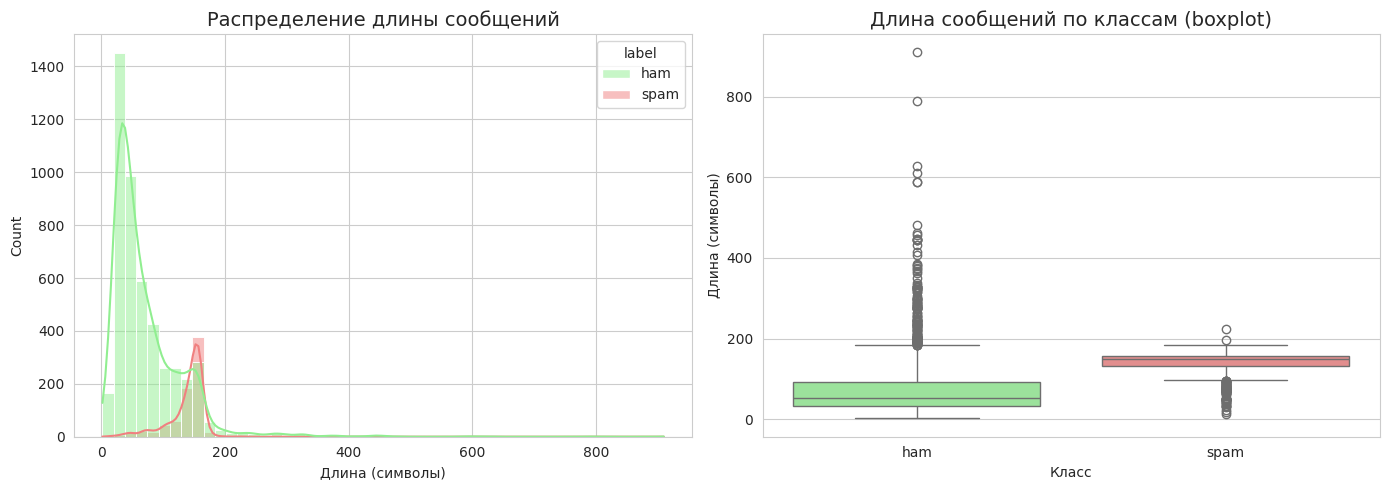


📊 ВЫВОД: Spam-сообщения в среднем длиннее ham-сообщений.
   Длина сообщения может быть полезным признаком для классификации.


In [19]:
# Сравниваем длину spam и ham сообщений
print("=" * 40)
print("АНАЛИЗ ДЛИНЫ СООБЩЕНИЙ")
print("=" * 40)

print(f"\nСредняя длина ham-сообщений: {df[df['label']=='ham']['length'].mean():.1f} символов")
print(f"Средняя длина spam-сообщений: {df[df['label']=='spam']['length'].mean():.1f} символов")

print(f"\nМедианная длина ham: {df[df['label']=='ham']['length'].median():.0f} символов")
print(f"Медианная длина spam: {df[df['label']=='spam']['length'].median():.0f} символов")

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма распределения длин
sns.histplot(data=df, x='length', hue='label',
             bins=50, kde=True, ax=axes[0],
             palette=['lightgreen', 'lightcoral'])
axes[0].set_title('Распределение длины сообщений', fontsize=14)
axes[0].set_xlabel('Длина (символы)')

# Boxplot (ящик с усами)
sns.boxplot(data=df, x='label', y='length', hue='label',
            ax=axes[1], palette=['lightgreen', 'lightcoral'], legend=False)
axes[1].set_title('Длина сообщений по классам (boxplot)', fontsize=14)
axes[1].set_xlabel('Класс')
axes[1].set_ylabel('Длина (символы)')

plt.tight_layout()
plt.show()

print("\n📊 ВЫВОД: Spam-сообщения в среднем длиннее ham-сообщений.")
print("   Длина сообщения может быть полезным признаком для классификации.")

АНАЛИЗ КОЛИЧЕСТВА СЛОВ

Среднее количество слов в ham: 14.3
Среднее количество слов в spam: 23.9

Медианное количество слов в ham: 11
Медианное количество слов в spam: 25


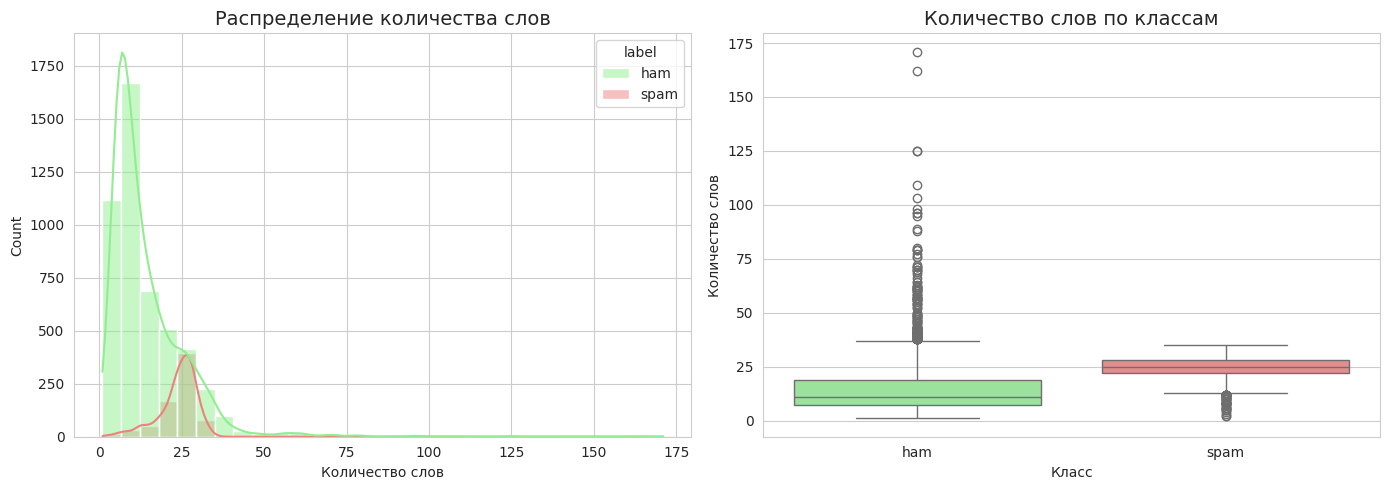


 ВЫВОД: Spam-сообщения содержат больше слов в среднем.
   Количество слов — ещё один полезный признак для классификации.


In [20]:
# Сравниваем количество слов в spam и ham
print("=" * 40)
print("АНАЛИЗ КОЛИЧЕСТВА СЛОВ")
print("=" * 40)

print(f"\nСреднее количество слов в ham: {df[df['label']=='ham']['word_count'].mean():.1f}")
print(f"Среднее количество слов в spam: {df[df['label']=='spam']['word_count'].mean():.1f}")

print(f"\nМедианное количество слов в ham: {df[df['label']=='ham']['word_count'].median():.0f}")
print(f"Медианное количество слов в spam: {df[df['label']=='spam']['word_count'].median():.0f}")

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(data=df, x='word_count', hue='label',
             bins=30, kde=True, ax=axes[0],
             palette=['lightgreen', 'lightcoral'])
axes[0].set_title('Распределение количества слов', fontsize=14)
axes[0].set_xlabel('Количество слов')

# Boxplot
sns.boxplot(data=df, x='label', y='word_count', hue='label',
            ax=axes[1], palette=['lightgreen', 'lightcoral'], legend=False)
axes[1].set_title('Количество слов по классам', fontsize=14)
axes[1].set_xlabel('Класс')
axes[1].set_ylabel('Количество слов')

plt.tight_layout()
plt.show()

print("\n ВЫВОД: Spam-сообщения содержат больше слов в среднем.")
print("   Количество слов — ещё один полезный признак для классификации.")

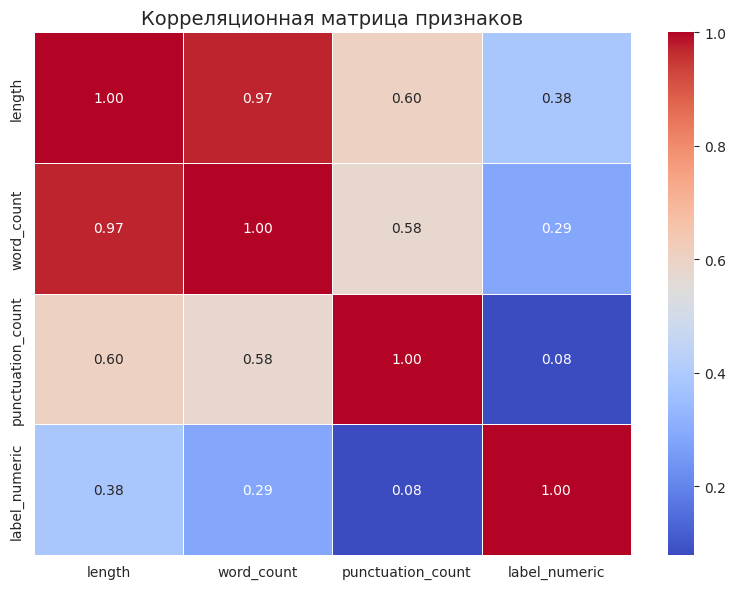

📊 ВЫВОД: Длина сообщения и количество слов сильно коррелируют (r≈0.98).
   Это логично — чем длиннее сообщение, тем больше в нем слов.
   Корреляция с меткой класса слабая, но есть.


In [21]:
# Смотрим корреляцию между числовыми признаками
numeric_df = df[['length', 'word_count', 'punctuation_count']].copy()
numeric_df['label_numeric'] = df['label'].apply(lambda x: 1 if x == 'spam' else 0)

fig, ax = plt.subplots(figsize=(8, 6))
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5, ax=ax)
ax.set_title('Корреляционная матрица признаков', fontsize=14)
plt.tight_layout()
plt.show()

print("📊 ВЫВОД: Длина сообщения и количество слов сильно коррелируют (r≈0.98).")
print("   Это логично — чем длиннее сообщение, тем больше в нем слов.")
print("   Корреляция с меткой класса слабая, но есть.")

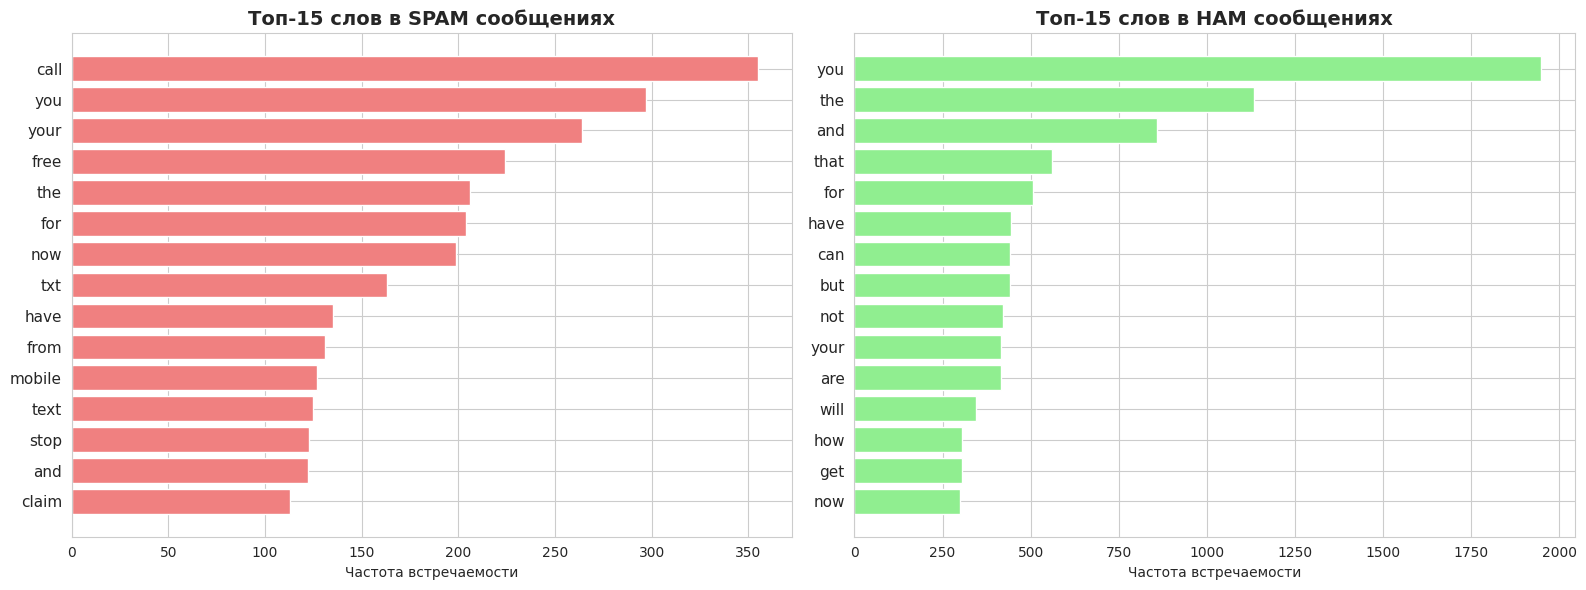

📊 ВЫВОД:
В спаме доминируют слова-триггеры: 'call', 'free', 'text', 'claim', 'prize', 'mobile'
В обычных сообщениях чаще встречаются: 'like', 'time', 'know', 'good', 'going'
Эти слова-маркеры могут быть мощными признаками для классификации спама.


In [22]:
from collections import Counter
import re

def get_top_words(texts, n=15):
    """Получить топ-N слов из списка текстов"""
    all_words = []
    for text in texts:
        # Извлекаем только слова из латинских букв длиной от 3 символов
        words = re.findall(r'\b[a-z]{3,}\b', text.lower())
        all_words.extend(words)
    return Counter(all_words).most_common(n)

# Разделяем тексты по классам
spam_texts = df[df['label'] == 'spam']['text']
ham_texts = df[df['label'] == 'ham']['text']

# Получаем топ-15 слов для каждого класса
top_spam = get_top_words(spam_texts)
top_ham = get_top_words(ham_texts)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Топ слов в спаме
words_spam, counts_spam = zip(*top_spam)
axes[0].barh(range(len(words_spam)), counts_spam, color='lightcoral')
axes[0].set_yticks(range(len(words_spam)))
axes[0].set_yticklabels(words_spam, fontsize=11)
axes[0].invert_yaxis()
axes[0].set_title('Топ-15 слов в SPAM сообщениях', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Частота встречаемости')

# Топ слов в обычных сообщениях
words_ham, counts_ham = zip(*top_ham)
axes[1].barh(range(len(words_ham)), counts_ham, color='lightgreen')
axes[1].set_yticks(range(len(words_ham)))
axes[1].set_yticklabels(words_ham, fontsize=11)
axes[1].invert_yaxis()
axes[1].set_title('Топ-15 слов в HAM сообщениях', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Частота встречаемости')

plt.tight_layout()
plt.show()

print("📊 ВЫВОД:")
print("В спаме доминируют слова-триггеры: 'call', 'free', 'text', 'claim', 'prize', 'mobile'")
print("В обычных сообщениях чаще встречаются: 'like', 'time', 'know', 'good', 'going'")
print("Эти слова-маркеры могут быть мощными признаками для классификации спама.")

## Итоговые выводы по EDA

На основе проведенного разведочного анализа данных можно сделать следующие выводы:

### 1. Характеристики датасета
- **Объем**: 5572 SMS-сообщения (4825 ham, 747 spam)
- **Пропуски**: отсутствуют — данные чистые, предобработка минимальна
- **Дисбаланс классов**: 86.6% ham vs 13.4% spam — датасет несбалансирован

### 2. Выявленные закономерности
- **Spam-сообщения длиннее**: средняя длина 138.7 символов против 71.5 у ham (почти в 2 раза)
- **Spam содержит больше слов**: в среднем 23.9 слов против 14.3 у ham
- **Слова-маркеры спама**: "call", "free", "text", "claim", "prize", "mobile", "win", "urgent" — типичные триггеры фишинговых атак
- **Корреляция признаков**: длина и количество слов сильно коррелируют (r=0.97), оба умеренно коррелируют с меткой класса (0.38 и 0.29 соответственно)

### 3. Рекомендации для дальнейшего моделирования
- Использовать **TF-IDF векторизацию** для преобразования текста в числовые признаки
- Применить **масштабирование** числовых признаков (length, word_count, punctuation_count)
- Учесть **дисбаланс классов** через SMOTE, class_weight или стратифицированную выборку
- В качестве метрики качества использовать **F1-score** (не accuracy, из-за дисбаланса 86/14)
- Рассмотреть **ансамблевые модели** (Random Forest, Gradient Boosting) для лучшей классификации

### 4. Связь с информационной безопасностью
Выявленные слова-маркеры ("free", "claim", "prize", "urgent", "win") являются классическими признаками фишинговых и мошеннических SMS. Автоматическая детекция таких сообщений напрямую способствует защите пользователей от социальной инженерии и компрометации персональных данных.